In [1]:
import sys
print(sys.executable)
import xgboost
print(xgboost.__version__)

C:\Users\Gopya\AppData\Local\Programs\Python\Python312\python.exe
3.4.1


In [5]:
import sys
sys.path.append("../src")
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from utils import load_split, evaluate

os.makedirs("../results", exist_ok=True)
os.makedirs("../figures", exist_ok=True)

paths = {
    "base": "../data/dataset_base.csv",
    "tech": "../data/dataset_with_technicals.csv",
}

In [6]:
param_dist = {
    "n_estimators":     [100, 200, 300],
    "max_depth":        [2, 3, 4],
    "learning_rate":    [0.01, 0.02, 0.05],
    "subsample":        [0.6, 0.8, 1.0],
    "colsample_bytree": [0.5, 0.7, 1.0],
    "min_child_weight": [1, 5, 10, 20],
    "reg_lambda":       [1, 10, 50, 100],
}

results, best_models = [], {}

for k, p in paths.items():
    print(f"--- {k}: starting ---", flush=True)
    X_tr, X_te, y_tr, y_te = load_split(p)
    mu = y_tr.mean()

    default = XGBRegressor(random_state=42, n_jobs=1)
    default.fit(X_tr, y_tr)
    results.append({**evaluate(y_te, default.predict(X_te), mu, "XGBoost (default)"), "data": k})

    search = RandomizedSearchCV(
        XGBRegressor(random_state=42, n_jobs=1),
        param_dist,
        n_iter=15,
        cv=TimeSeriesSplit(n_splits=3),
        scoring="neg_root_mean_squared_error",
        random_state=42,
        n_jobs=1,
    )
    search.fit(X_tr, y_tr)
    print(f"[{k}] best params: {search.best_params_}", flush=True)
    print(f"[{k}] best CV RMSE: {-search.best_score_:.4f}", flush=True)

    best_models[k] = search.best_estimator_
    results.append({**evaluate(y_te, search.predict(X_te), mu, "XGBoost (tuned)"), "data": k})

res = pd.DataFrame(results).set_index(["data", "model"])
print(res.round(4))
res.to_csv("../results/xgboost_results.csv")

--- base: starting ---
[base] best params: {'subsample': 0.6, 'reg_lambda': 50, 'n_estimators': 100, 'min_child_weight': 1, 'max_depth': 3, 'learning_rate': 0.02, 'colsample_bytree': 1.0}
[base] best CV RMSE: 0.0327
--- tech: starting ---
[tech] best params: {'subsample': 0.6, 'reg_lambda': 50, 'n_estimators': 100, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.01, 'colsample_bytree': 0.5}
[tech] best CV RMSE: 0.0324
                          RMSE     MAE      R2  R2_OOS  DirAcc
data model                                                    
base XGBoost (default)  0.0381  0.0278 -0.0808 -0.0795  0.4914
     XGBoost (tuned)    0.0366  0.0261  0.0059  0.0071  0.5429
tech XGBoost (default)  0.0388  0.0272 -0.1096 -0.1085  0.5318
     XGBoost (tuned)    0.0368  0.0261 -0.0005  0.0004  0.5260


In [7]:
base = pd.read_csv("../results/baseline_results.csv", index_col=[0, 1])
combined = pd.concat([base, res]).sort_index()
print(combined.round(4))

                          RMSE     MAE      R2  R2_OOS  DirAcc
data model                                                    
base Linear regression  0.0364  0.0265  0.0167  0.0179  0.4514
     Ridge              0.0366  0.0260  0.0060  0.0072  0.5086
     Train mean         0.0367  0.0260 -0.0012  0.0000  0.5200
     XGBoost (default)  0.0381  0.0278 -0.0808 -0.0795  0.4914
     XGBoost (tuned)    0.0366  0.0261  0.0059  0.0071  0.5429
     Zero forecast      0.0368  0.0258 -0.0078 -0.0065  0.4800
tech Linear regression  0.0366  0.0268  0.0153  0.0162  0.4509
     Ridge              0.0368  0.0262  0.0023  0.0033  0.5145
     Train mean         0.0369  0.0260 -0.0010  0.0000  0.5202
     XGBoost (default)  0.0388  0.0272 -0.1096 -0.1085  0.5318
     XGBoost (tuned)    0.0368  0.0261 -0.0005  0.0004  0.5260
     Zero forecast      0.0370  0.0259 -0.0080 -0.0071  0.4798


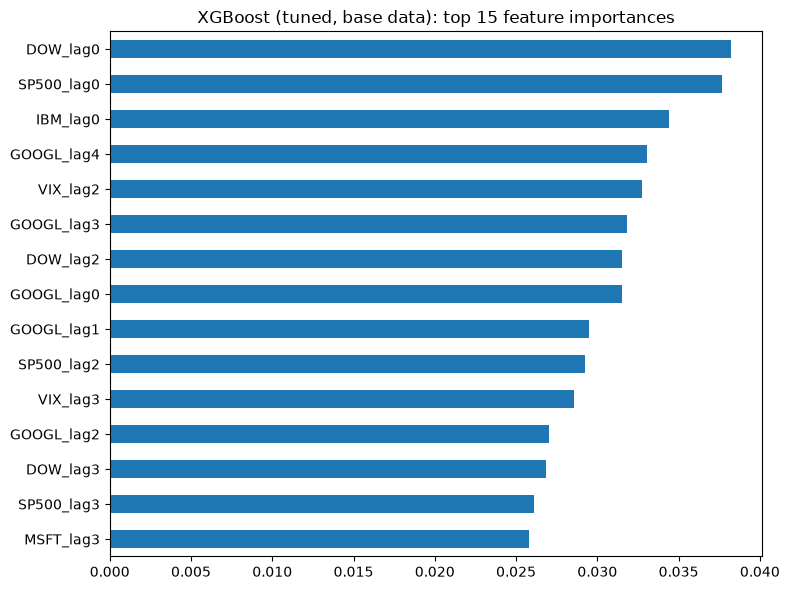

DOW_lag0      0.0382
SP500_lag0    0.0377
IBM_lag0      0.0344
GOOGL_lag4    0.0331
VIX_lag2      0.0327
GOOGL_lag3    0.0318
DOW_lag2      0.0315
GOOGL_lag0    0.0315
GOOGL_lag1    0.0295
SP500_lag2    0.0292
dtype: float32


In [8]:
model = best_models["base"]
X_tr, X_te, y_tr, y_te = load_split(paths["base"])

imp = pd.Series(model.feature_importances_, index=X_tr.columns).sort_values()
imp.tail(15).plot.barh(figsize=(8, 6), title="XGBoost (tuned, base data): top 15 feature importances")
plt.tight_layout()
plt.savefig("../figures/08_xgb_feature_importance.png", dpi=150)
plt.show()
print(imp.sort_values(ascending=False).head(10).round(4))

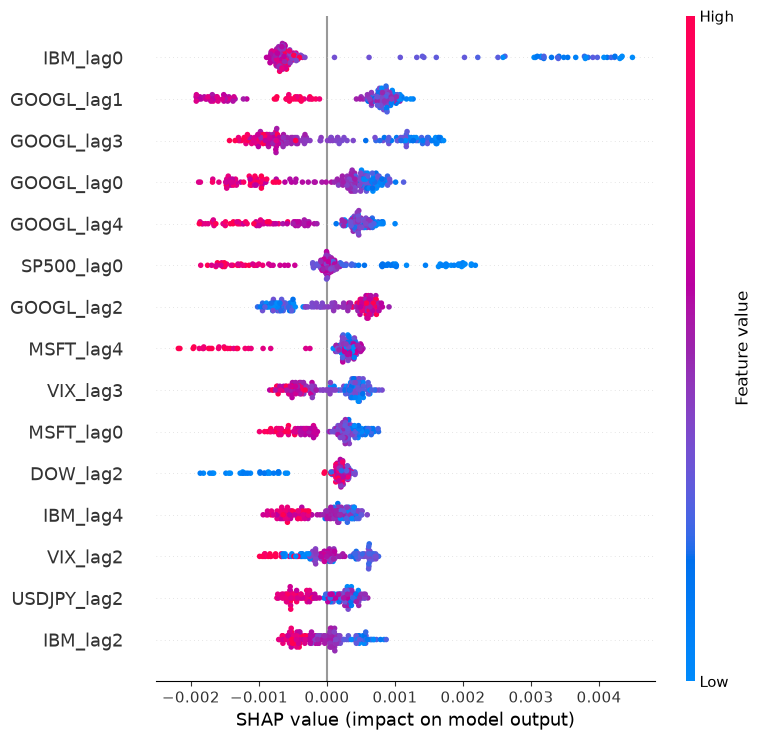

In [9]:
import shap

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_te)

shap.summary_plot(shap_values, X_te, show=False, max_display=15)
plt.tight_layout()
plt.savefig("../figures/09_xgb_shap.png", dpi=150, bbox_inches="tight")
plt.show()

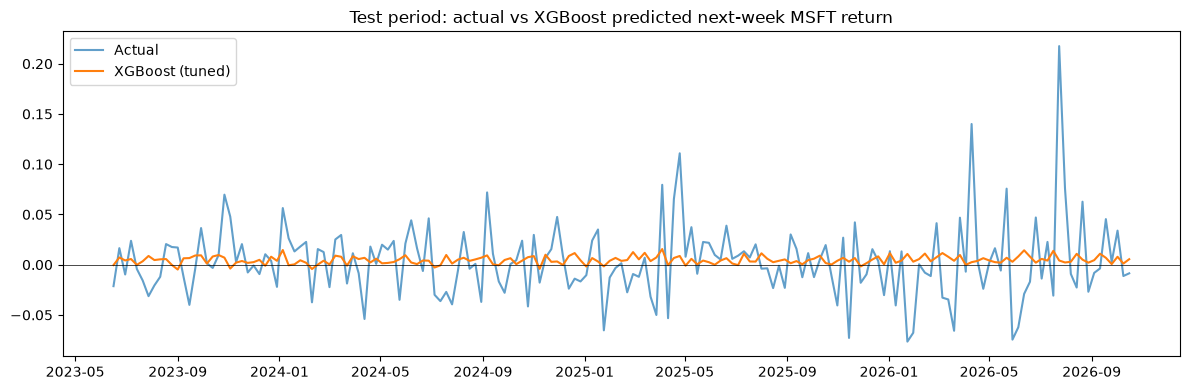

In [10]:
pred = model.predict(X_te)

plt.figure(figsize=(12, 4))
plt.plot(y_te.index, y_te.values, label="Actual", alpha=0.7)
plt.plot(y_te.index, pred, label="XGBoost (tuned)")
plt.axhline(0, color="k", lw=0.5)
plt.title("Test period: actual vs XGBoost predicted next-week MSFT return")
plt.legend()
plt.tight_layout()
plt.savefig("../figures/10_xgb_pred_vs_actual.png", dpi=150)
plt.show()